In [22]:

import sys
import gc
from pathlib import Path
import numpy as np
import torch
from torch.utils.data import DataLoader
ROOT_DIR=Path(r'D:\MyJupyter\Works\FaceScore')
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0,str(ROOT_DIR))
from model import SparseLandauScoreField
from others import create_baseline
from rating_dataset import RatingDataset
TEST_DIR=ROOT_DIR/'data'/'test_face_data'
WEIGHTS_DIR=ROOT_DIR/'weights'
SEEDS=[42,123,2026,3407,777]
IMAGE_IDS=['3821','2919','2922','2963','3767','3220','3172','3461','3529','3693','3848','3052','3245','3310','3478','3591','3684','3127','3315','3472']
IMAGE_SIZE=336
BATCH_SIZE=2
HEAD_BATCH_SIZE=64
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP=DEVICE.type=='cuda'
if not TEST_DIR.is_dir():
    raise FileNotFoundError(f'测试集不存在: {TEST_DIR}')
if len(IMAGE_IDS)!=20 or len(set(str(item).casefold() for item in IMAGE_IDS))!=20:
    raise ValueError('IMAGE_IDS必须包含20个不同的图片编号')
checkpoint_paths=[WEIGHTS_DIR/f'ours_{seed}.pt' for seed in SEEDS]
for path in checkpoint_paths:
    if not path.is_file():
        raise FileNotFoundError(f'缺少模型权重: {path}')
all_image_paths=sorted(path for path in TEST_DIR.iterdir() if path.suffix.lower() in ('.jpg','.jpeg','.png'))
image_lookup={path.stem.casefold():index for index,path in enumerate(all_image_paths)}
if len(image_lookup)!=len(all_image_paths):
    raise RuntimeError('测试集存在重复图片编号')
selected_indices=[]
for item in IMAGE_IDS:
    image_id=Path(str(item)).stem.casefold()
    if image_id not in image_lookup:
        raise FileNotFoundError(f'测试集中找不到图片编号: {item}，请将IMAGE_IDS改成真实存在的编号')
    selected_indices.append(image_lookup[image_id])
test_dataset=RatingDataset(str(TEST_DIR),indices=selected_indices,mask_dir=None,augment=False,repeat=1,image_size=IMAGE_SIZE,soft_target=False)
test_loader=DataLoader(test_dataset,batch_size=BATCH_SIZE,shuffle=False,num_workers=0,pin_memory=USE_AMP)
class FrozenEncoderTokenAdapter(torch.nn.Module):
    def __init__(self,encoder,input_size,mean,std):
        super().__init__()
        self.encoder=encoder
        self.embed_dim=int(encoder.num_features)
        self.global_only=True
        self.input_size=int(input_size)
        self.register_buffer('mean',mean.detach().clone())
        self.register_buffer('std',std.detach().clone())
    def get_intermediate_layers(self,x,n=3,return_class_token=True,norm=True):
        features=self.encoder(x)
        tokens=features.unsqueeze(1)
        return [(tokens,features) for _ in range(3)]
    def train(self,mode=True):
        super().train(mode)
        self.encoder.eval()
        return self
tip_encoder=create_baseline('TIPSV2',pretrained=False,freeze_backbone=True,dropout=0.0)
tip_adapter=FrozenEncoderTokenAdapter(tip_encoder.backbone,tip_encoder.input_size,tip_encoder.mean,tip_encoder.std)
model=SparseLandauScoreField(pretrained=False,backbone=tip_adapter,dropout=0.10,train_last_stage=False,width=24,prior_mix=0.0,use_entropy=False,use_high_resolution=False,scales=(224,),grid_side=16,use_evidence_head=True,evidence_base=0.1,use_global_token=True).to(DEVICE)
reference_state=torch.load(checkpoint_paths[0],map_location='cpu',weights_only=True)
model.load_state_dict(reference_state,strict=True)
model.eval()
feature_parts=[]
target_parts=[]
with torch.inference_mode():
    for images,targets in test_loader:
        images=images.to(DEVICE,non_blocking=True)
        with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=USE_AMP):
            features=model.encode_features(images)
        feature_parts.append(features.float().cpu())
        target_parts.append(targets.float().cpu())
test_features=torch.cat(feature_parts,dim=0)
test_targets=torch.cat(target_parts,dim=0).numpy().astype(np.float64)
prediction_sets=[]
for seed,path in zip(SEEDS,checkpoint_paths):
    state=reference_state if seed==SEEDS[0] else torch.load(path,map_location='cpu',weights_only=True)
    if seed!=SEEDS[0]:
        for name,value in reference_state.items():
            if name.startswith('backbone.') or name in ('mean','std'):
                if name not in state or not torch.equal(value,state[name]):
                    raise RuntimeError(f'{path.name}的冻结编码器或标准化参数不一致，不能共享测试特征: {name}')
    model.load_state_dict(state,strict=True)
    model.eval()
    prediction_parts=[]
    with torch.inference_mode():
        for start in range(0,len(test_features),HEAD_BATCH_SIZE):
            batch=test_features[start:start+HEAD_BATCH_SIZE].to(DEVICE,non_blocking=True)
            with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=USE_AMP):
                log_probs,_=model.forward_from_features(batch)
            probabilities=log_probs.float().exp()
            prediction_parts.append(probabilities.cpu().numpy().astype(np.float64))
    seed_predictions=np.concatenate(prediction_parts,axis=0)
    if not np.isfinite(seed_predictions).all() or not np.allclose(seed_predictions.sum(axis=1),1.0,atol=1e-5):
        raise RuntimeError(f'{path.name}产生无效预测分布')
    prediction_sets.append(seed_predictions)
    print(f'已完成预测: {path.name}',flush=True)
    if seed!=SEEDS[0]:
        del state
all_predictions={'ours':np.stack(prediction_sets,axis=0)}
if all_predictions['ours'].shape!=(len(SEEDS),len(test_dataset),10):
    raise RuntimeError('预测结果维度异常')
del model,tip_encoder,tip_adapter,reference_state,feature_parts,target_parts,prediction_parts
gc.collect()
if USE_AMP:
    torch.cuda.empty_cache()
print(f'已完成 {len(test_dataset)} 张图片 × {len(SEEDS)} 个模型权重的预测')
print(f'all_predictions["ours"]形状: {all_predictions["ours"].shape}')
print(f'test_targets形状: {test_targets.shape}')
print('可以直接运行下一个可视化单元格')


已完成预测: ours_42.pt
已完成预测: ours_123.pt
已完成预测: ours_2026.pt
已完成预测: ours_3407.pt
已完成预测: ours_777.pt
已完成 20 张图片 × 5 个模型权重的预测
all_predictions["ours"]形状: (5, 20, 10)
test_targets形状: (20, 10)
可以直接运行下一个可视化单元格


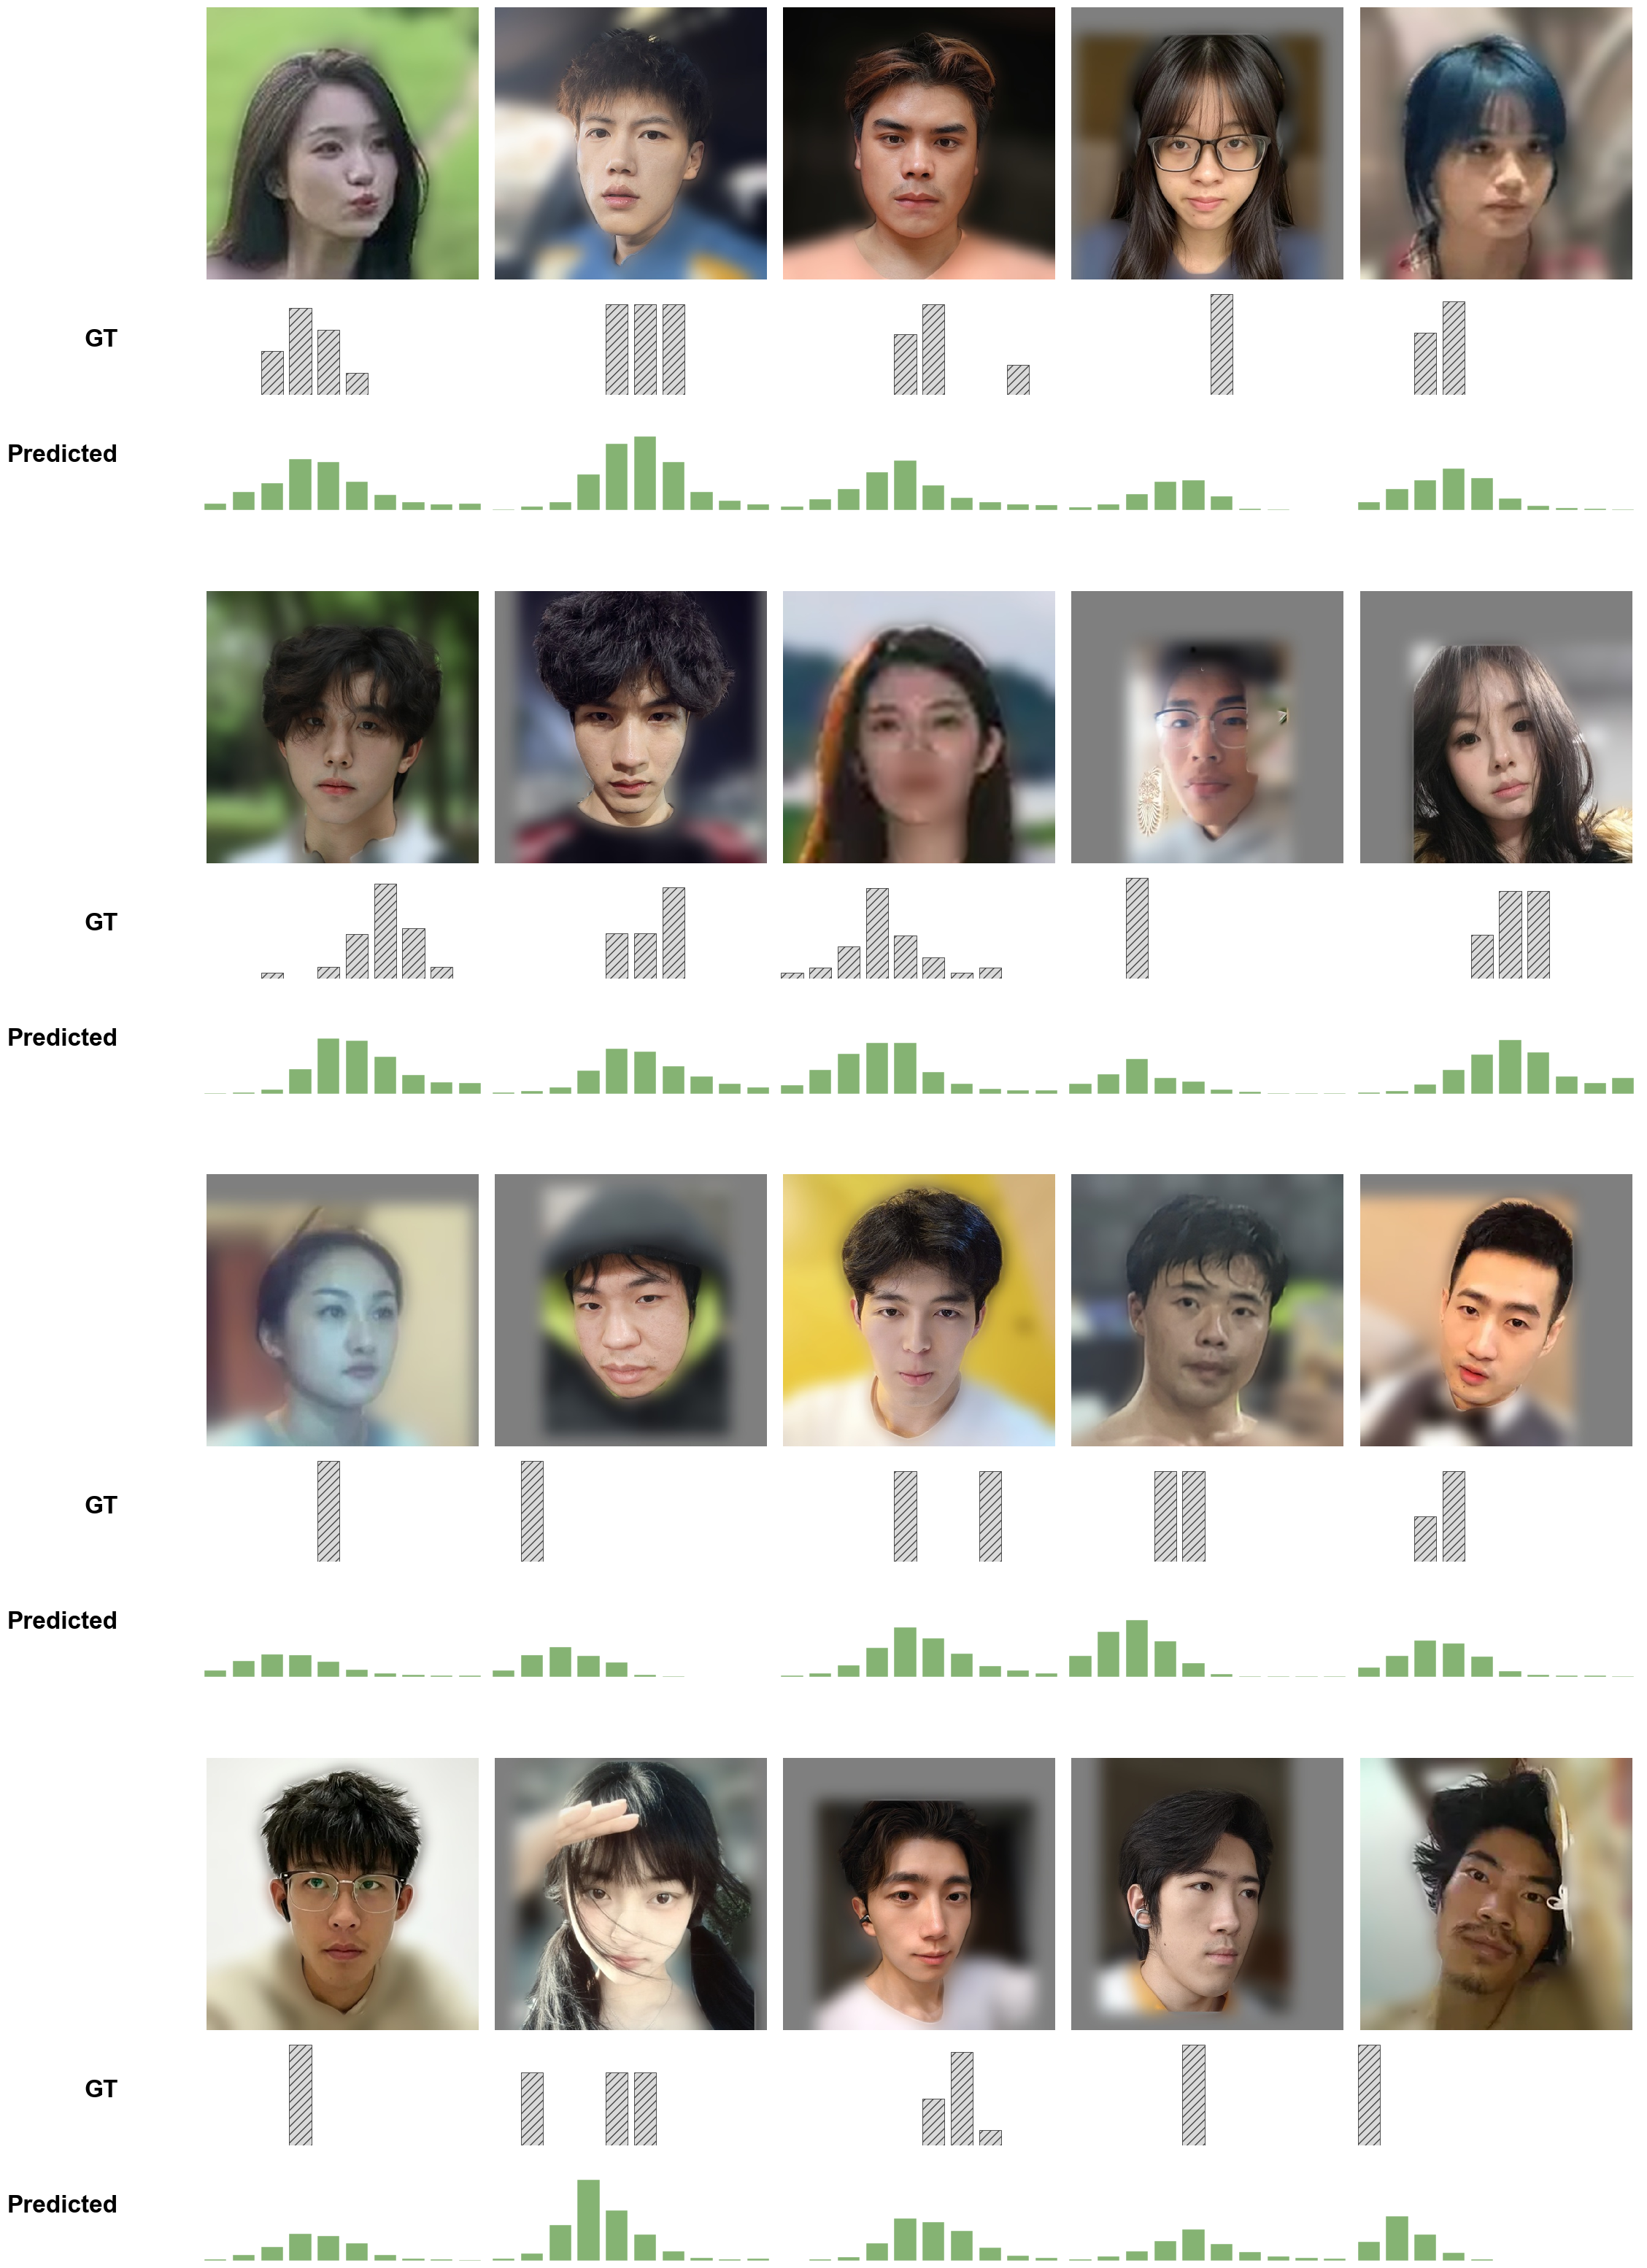

图像已保存到: D:\MyJupyter\Works\FaceScore\outputs\figures\ours_distribution_showcase.pdf
图片编号: 3821, 2919, 2922, 2963, 3767, 3220, 3172, 3461, 3529, 3693, 3848, 3052, 3245, 3310, 3478, 3591, 3684, 3127, 3315, 3472
模型预测: 5个训练种子的平均概率分布


In [23]:
from pathlib import Path
from PIL import Image,ImageOps
import numpy as np
import matplotlib.pyplot as plt
ROOT_DIR=Path(r'D:\MyJupyter\Works\FaceScore')
CROPPED_TEST_DIR=ROOT_DIR/'data'/'test_face_data'
FIGURE_DIR=ROOT_DIR/'outputs'/'figures'
IMAGE_IDS=['3821','2919','2922','2963','3767','3220','3172','3461','3529','3693','3848','3052','3245','3310','3478','3591','3684','3127','3315','3472']
PLOT_MODE='mean'
DISPLAY_SEED=42
FIGURE_WIDTH=22
FIGURE_HEIGHT=32
PHOTO_ROW_RATIO=2.5
DISTRIBUTION_ROW_RATIO=1.0
LEFT_MARGIN=0.10
RIGHT_MARGIN=0.998
TOP_MARGIN=0.99
BOTTOM_MARGIN=0.025
IMAGE_WSPACE=0.0
IMAGE_HSPACE=0.04
BLOCK_HSPACE=0.20
GROUP_HSPACE=0.16
IMAGE_DISPLAY_SIZE=800
IMAGE_PAD_COLOR='#F5F5F5'
ROW_LABEL_SIZE=24
ROW_LABEL_X_OFFSET=0.05
BAR_WIDTH=0.78
SAVE_DPI=800
SAVE_NAME='ours_distribution_showcase.pdf'
SAME_Y_SCALE=True
OURS_COLOR='#85B373'
GT_COLOR='#D9D9D9'
DISPLAY_NAME='Ours (SSE)'
if len(IMAGE_IDS)!=20 or len({str(item).casefold() for item in IMAGE_IDS})!=20:
    raise ValueError('IMAGE_IDS必须包含20个不同的图片编号')
if PLOT_MODE not in ('mean','seed'):
    raise ValueError("PLOT_MODE必须是'mean'或'seed'")
if PLOT_MODE=='seed' and DISPLAY_SEED not in SEEDS:
    raise ValueError(f'DISPLAY_SEED必须在{SEEDS}中')
if not CROPPED_TEST_DIR.is_dir():
    raise FileNotFoundError(f'缺少裁剪测试图目录: {CROPPED_TEST_DIR}')
if 'ours' not in all_predictions:
    raise KeyError("all_predictions中不存在'ours'")
image_paths=[Path(path) for path in test_dataset.image_paths]
if any(path.parent.resolve()!=CROPPED_TEST_DIR.resolve() for path in image_paths):
    raise RuntimeError('当前test_dataset不是从test_face_data加载的，请先核对测试集顺序')
if len(image_paths)!=len(test_targets):
    raise RuntimeError('测试图片数量与真实标签数量不一致')
image_lookup={path.stem.casefold():i for i,path in enumerate(image_paths)}
if len(image_lookup)!=len(image_paths):
    raise RuntimeError('裁剪测试集存在相同编号但扩展名不同的照片')
selected_indices=[]
for item in IMAGE_IDS:
    image_id=Path(str(item)).stem.casefold()
    if image_id not in image_lookup:
        raise FileNotFoundError(f'裁剪测试集中没有编号: {item}')
    selected_indices.append(image_lookup[image_id])
ours_values=np.asarray(all_predictions['ours'],dtype=np.float64)
if ours_values.shape!=(len(SEEDS),len(image_paths),10):
    raise RuntimeError(f"ours的预测结果维度不正确: {ours_values.shape}")
if not np.isfinite(ours_values).all() or (ours_values<0).any() or not np.allclose(ours_values.sum(axis=2),1.0,atol=1e-5):
    raise RuntimeError('ours包含无效预测概率')
predictions_display=ours_values.mean(axis=0) if PLOT_MODE=='mean' else ours_values[SEEDS.index(DISPLAY_SEED)]
plt.rcParams['font.family']='Arial'
plt.rcParams['font.sans-serif']=['Arial']
plt.rcParams['axes.unicode_minus']=False
plt.rcParams['pdf.fonttype']=42
plt.rcParams['ps.fonttype']=42
fig=plt.figure(figsize=(FIGURE_WIDTH,FIGURE_HEIGHT))
outer_grid=fig.add_gridspec(4,1,hspace=GROUP_HSPACE)
axes_groups=[]
for group_index in range(4):
    group_grid=outer_grid[group_index].subgridspec(3,5,height_ratios=[PHOTO_ROW_RATIO,DISTRIBUTION_ROW_RATIO,DISTRIBUTION_ROW_RATIO],wspace=IMAGE_WSPACE,hspace=IMAGE_HSPACE)
    group_axes=[[fig.add_subplot(group_grid[row,col]) for col in range(5)] for row in range(3)]
    axes_groups.append(group_axes)
fig.subplots_adjust(left=LEFT_MARGIN,right=RIGHT_MARGIN,top=TOP_MARGIN,bottom=BOTTOM_MARGIN)
resample=Image.Resampling.LANCZOS if hasattr(Image,'Resampling') else Image.LANCZOS
score_bins=np.arange(1,11,dtype=np.float64)
for group_index in range(4):
    group_indices=selected_indices[group_index*5:(group_index+1)*5]
    group_axes=axes_groups[group_index]
    for col,index in enumerate(group_indices):
        cropped_path=image_paths[index]
        with Image.open(cropped_path) as source:
            rgb=ImageOps.exif_transpose(source).convert('RGB')
            display_image=ImageOps.pad(rgb,(IMAGE_DISPLAY_SIZE,IMAGE_DISPLAY_SIZE),method=resample,color=IMAGE_PAD_COLOR)
        image_axis=group_axes[0][col]
        image_axis.imshow(display_image,interpolation='nearest')
        image_axis.axis('off')
        target=np.asarray(test_targets[index],dtype=np.float64)
        if target.shape!=(10,) or not np.isfinite(target).all() or (target<0).any() or not np.isclose(target.sum(),1.0,atol=1e-5):
            raise RuntimeError(f'{cropped_path.name}的真实评分分布无效')
        prediction=np.asarray(predictions_display[index],dtype=np.float64)
        if prediction.shape!=(10,) or not np.isfinite(prediction).all() or (prediction<0).any() or not np.isclose(prediction.sum(),1.0,atol=1e-5):
            raise RuntimeError(f'{cropped_path.name}的ours预测分布无效')
        ymax=min(1.08,max(0.25,np.ceil(max(float(np.max(target)),float(np.max(prediction)))*11.0)/10.0))
        gt_axis=group_axes[1][col]
        gt_axis.bar(score_bins,target,width=BAR_WIDTH,color=GT_COLOR,edgecolor='#444444',linewidth=0.65,hatch='///',zorder=3)
        gt_axis.set_xlim(0.4,10.6)
        gt_axis.set_ylim(0,ymax if SAME_Y_SCALE else min(1.08,max(0.15,float(np.max(target))*1.15)))
        gt_axis.axis('off')
        pred_axis=group_axes[2][col]
        pred_axis.bar(score_bins,prediction,width=BAR_WIDTH,color=OURS_COLOR,edgecolor='white',linewidth=0.35,zorder=3)
        pred_axis.set_xlim(0.4,10.6)
        pred_axis.set_ylim(0,ymax if SAME_Y_SCALE else min(1.08,max(0.15,float(np.max(prediction))*1.15)))
        pred_axis.axis('off')
row_names=['','GT','Predicted']
for group_index in range(4):
    group_axes=axes_groups[group_index]
    for row,row_name in enumerate(row_names):
        position=group_axes[row][0].get_position()
        fig.text(position.x0-ROW_LABEL_X_OFFSET,(position.y0+position.y1)/2,row_name,fontsize=ROW_LABEL_SIZE,fontfamily='Arial',ha='right',va='center',fontweight='bold')
FIGURE_DIR.mkdir(parents=True,exist_ok=True)
figure_path=FIGURE_DIR/SAVE_NAME
fig.savefig(figure_path,dpi=SAVE_DPI,bbox_inches='tight',facecolor='white')
plt.show()
plt.close(fig)
print(f'图像已保存到: {figure_path}')
print('图片编号: '+', '.join(image_paths[i].stem for i in selected_indices))
print('模型预测: 5个训练种子的平均概率分布' if PLOT_MODE=='mean' else f'模型预测: 随机种子{DISPLAY_SEED}')